---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 3"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 10. Активні фільтри: класифікація, поліноми, елементарні ланки</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>3.1. Активні фільтри, основні визначення та класифікація; що таке порядок фільтра</li>
  <li>3.2. Основні типи фільтрів за призначенням та типом полінома</li>
  <li>3.3. Елементарні виборчі кола, які використовуються при побудові активних фільтрів: основні типи та розрахункові співвідношення</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 10 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Активні фільтри: визначення, класифікація, порядок](#filters-basics)
* [Типи фільтрів за призначенням і типом полінома](#filter-types)
    * [🔬 Інтерактивно: порівняння апроксимацій: АЧХ, групова затримка, перехідна характеристика](#approx-interactive)
* [Елементарні виборчі кола](#rc-circuits)
    * [🔬 Інтерактивно: АЧХ і ФЧХ елементарних виборчих кіл](#rc-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Активні фільтри: визначення, класифікація, порядок <a class="anchor" id="filters-basics"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.1</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Давати визначення електричного фільтра, смуги пропускання і затримування
> - Пояснювати переваги активних фільтрів над пасивними LC-фільтрами
> - Визначати порядок фільтра за передавальною функцією і схемою

</div>

**Електричний фільтр** — частотновибіркове коло, яке пропускає сигнали в певній смузі частот (**смуга пропускання**, СП) і послаблює сигнали поза нею (**смуга затримування**, СЗ). Між ними лежить **перехідна смуга**.

**Активний фільтр** — фільтр, що містить, крім пасивних $R$ і $C$, активний елемент (найчастіше ОП). Порівняно з пасивними LC-фільтрами:
- немає котушок індуктивності — громіздких, дорогих і неточних на низьких частотах (до сотень кілогерц), а мікросхемне виконання стає можливим;
- можна отримати **підсилення** в СП і добротність до сотень лише на $R$ і $C$;
- великий вхідний і малий вихідний опір — ланки можна з'єднувати каскадно **без взаємного впливу**, тож фільтр високого порядку будують з простих ланок 1-го і 2-го порядку;
- легка перебудова (змінними резисторами).

Недоліки: потрібне живлення; робочі частоти обмежені частотою $f_1$ і швидкістю наростання ОП (зазвичай до сотень кілогерц – одиниць мегагерц); власні шуми ОП; обмежений динамічний діапазон.

### Передавальна функція і порядок

Лінійний фільтр описується передавальною функцією — відношенням двох поліномів від $p = j\omega$:
$$K(p) = \frac{b_mp^m + \ldots + b_1p + b_0}{a_np^n + \ldots + a_1p + a_0} .$$
**Порядок фільтра** $n$ — степінь полінома знаменника (кількість полюсів). Він дорівнює числу незалежних реактивних елементів (конденсаторів) у схемі і визначає **крутизну спаду** АЧХ поза СП: асимптотично **$20n$ дБ/декаду** ($6n$ дБ/октаву). Чим вищий порядок, тим ближча АЧХ до ідеальної прямокутної, але тим складніша схема і гірші фазові властивості.

Будь-який поліном знаменника можна розкласти на множники 1-го і 2-го порядку, тому фільтр $n$-го порядку будують каскадним з'єднанням $\lfloor n/2\rfloor$ ланок 2-го порядку (і однієї ланки 1-го порядку при непарному $n$). Ланка 2-го порядку характеризується **частотою полюса** $\omega_0$ і **добротністю полюса** $Q$:
$$K_{ФНЧ}(p) = \frac{K_0\,\omega_0^2}{p^2 + \frac{\omega_0}{Q}p + \omega_0^2}.$$

### Класифікація

| Ознака | Види |
|---|---|
| За призначенням (видом АЧХ) | ФНЧ, ФВЧ, смуговий (СФ), загороджувальний (режекторний, ЗФ), фазовий (всепропускний) |
| За апроксимацією (типом полінома) | Баттерворта, Чебишова, інверсний Чебишова, еліптичний (Кауера), Бесселя (Томсона), Лежандра |
| За порядком | 1-го, 2-го, …, $n$-го |
| За схемотехнікою ланок | з багатопетлевим ЗЗ (MFB), Саллена–Кі (з джерелом напруги, керованим напругою), біквадратні (зі змінними станами), на гіраторах, на перемикальних конденсаторах |
| За елементною базою | пасивні RC, LC; активні RC; цифрові |

---

## Типи фільтрів за призначенням і типом полінома <a class="anchor" id="filter-types"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.2</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Розрізняти ФНЧ, ФВЧ, СФ, ЗФ і фазові фільтри за АЧХ
> - Порівнювати апроксимації Баттерворта, Чебишова, Бесселя, еліптичну за АЧХ, ФЧХ і перехідною характеристикою
> - Вибирати порядок фільтра за вимогами до послаблення

</div>

### За призначенням

| Тип | АЧХ (ідеальна) | Приклад застосування |
|---|---|---|
| **ФНЧ** | пропускає $0 < f < f_з$ | антиелайзинговий фільтр перед АЦП, згладжування ЦАП і ШІМ, виділення огинаючої |
| **ФВЧ** | пропускає $f > f_з$ | усунення постійної складової і дрейфу, фільтр для ВЧ-динаміка (кросовер) |
| **Смуговий (СФ)** | пропускає $f_н < f < f_в$ | виділення каналу, тональні детектори, еквалайзери |
| **Загороджувальний (ЗФ, режекторний)** | пригнічує вузьку смугу навколо $f_0$ | придушення мережевої завади 50 Гц |
| **Фазовий (всепропускний)** | $|K| = 1$ на всіх частотах, змінюється лише фаза | фазові коректори, лінії затримки, фазообертачі |

### За типом полінома (апроксимації)

Ідеальну прямокутну АЧХ реалізувати неможливо; її **апроксимують** функціями, що дають різні компроміси:
$$|K(j\omega)|^2 = \frac{K_0^2}{1 + \varepsilon^2F_n^2(\omega/\omega_з)}.$$

- **Баттерворта** ($F_n = (\omega/\omega_з)^n$): **максимально плоска** АЧХ у СП, монотонний спад; на частоті зрізу −3 дБ. Компроміс «за замовчуванням». $|K| = K_0/\sqrt{1 + (\omega/\omega_з)^{2n}}$.
- **Чебишова (I роду)** ($F_n$ — поліноми Чебишова): **рівнохвильові пульсації** в СП (0,1…3 дБ) за рахунок **крутішого спаду** в перехідній смузі; гірша ФЧХ і більший викид перехідної характеристики.
- **Інверсний Чебишова (II роду)**: плоска СП і пульсації в СЗ (нулі передачі).
- **Еліптичний (Кауера)**: пульсації і в СП, і в СЗ; **найкрутіший спад** при заданому порядку; найскладніший.
- **Бесселя (Томсона)**: **максимально лінійна ФЧХ** (стала групова затримка) — імпульси передаються без викиду і дзвону, але спад найпологіший. Для імпульсних і цифрових сигналів, осцилографів.

**Вибір порядку** (Баттерворт): щоб на частоті $f_з$ мати послаблення $A_з$ дБ,
$$n \ge \frac{\lg\left(10^{A_з/10} - 1\right)}{2\lg(f_з/f_c)} .$$

---
### 🔬 Інтерактивно: порівняння апроксимацій: АЧХ, групова затримка, перехідна характеристика <a class="anchor" id="approx-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

ФНЧ з частотою зрізу 1 кГц ($f_c$) однакового порядку $n$ за різними апроксимаціями (розраховано `scipy.signal`). Збільшуйте порядок і пульсації Чебишова: спад крутішає, але групова затримка стає нерівномірною, а перехідна характеристика — коливальною. Фільтр Бесселя спадає повільно, зате імпульс передає без викиду.

</div>

In [2]:
# ФНЧ n-го порядку: Баттерворт, Чебишов I, Бессель, еліптичний — АЧХ, групова затримка, перехідна характеристика
def approx(n=4, ripple=1.0):
    wc = 2 * np.pi * 1e3
    filt = {
        'Баттерворта': signal.butter(n, wc, analog=True),
        f'Чебишова ({ripple:g} дБ)': signal.cheby1(n, ripple, wc, analog=True),
        'Бесселя': signal.bessel(n, wc, analog=True, norm='mag'),
        f'еліптичний ({ripple:g} / 50 дБ)': signal.ellip(n, ripple, 50, wc, analog=True),
    }
    cols = ['#2196F3', '#F44336', '#4CAF50', '#9C27B0']
    w = 2 * np.pi * np.logspace(1.5, 4.5, 2000)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for (name, (b, a)), col in zip(filt.items(), cols):
        _, h = signal.freqs(b, a, w)
        ax[0].semilogx(w / 2 / np.pi, db(h), color=col, label=name)
        ph = np.unwrap(np.angle(h)); gd = -np.gradient(ph, w)
        ax[1].semilogx(w / 2 / np.pi, gd * 1e3, color=col)
        t, y = signal.step((b, a), T=np.linspace(0, 6e-3, 2000))
        ax[2].plot(t * 1e3, y, color=col)
    ax[0].set_ylim(-80, 5); ax[0].axhline(-3, color='k', ls=':', lw=1); ax[0].set_xlabel('f, Гц'); ax[0].set_ylabel('дБ')
    ax[0].set_title(f'АЧХ, n = {n}'); ax[0].legend(fontsize=8, loc='lower left')
    ax[1].set_xlabel('f, Гц'); ax[1].set_ylabel('мс'); ax[1].set_title('Групова затримка (у СП)'); ax[1].set_xlim(30, 2e3); ax[1].set_ylim(0, 1.6)
    ax[2].axhline(1, color='k', lw=0.8); ax[2].set_xlabel('t, мс'); ax[2].set_title('Перехідна характеристика')
    plt.tight_layout(); plt.show()
    print(f'Асимптотичний нахил АЧХ: −{20*n} дБ/дек;  Баттерворт на 2fc: {-10*np.log10(1 + 2**(2*n)):.1f} дБ')

interact(approx,
         n=widgets.IntSlider(min=1, max=8, value=4, description='порядок n'),
         ripple=widgets.FloatSlider(min=0.1, max=3, step=0.1, value=1.0, description='пульсації (дБ)'));

interactive(children=(IntSlider(value=4, description='порядок n', max=8, min=1), FloatSlider(value=1.0, descri…

---

## Елементарні виборчі кола <a class="anchor" id="rc-circuits"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.3</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Знати передавальні функції RC-ланок 1-го порядку (ФНЧ, ФВЧ)
> - Розраховувати міст Віна і подвійний Т-міст
> - Пояснювати, як пасивні виборчі кола використовуються в активних фільтрах і генераторах

</div>

Активний фільтр — це пасивне RC-коло, увімкнене на вході або в колі ЗЗ підсилювача. Основні елементарні кола:

**1. Інтегрувальна RC-ланка (ФНЧ 1-го порядку):**
$$K(j\omega) = \frac{1}{1 + j\omega RC},\qquad f_з = \frac{1}{2\pi RC},\qquad \varphi = -\arctan\omega RC\;(0\ldots-90°).$$

**2. Диференціювальна CR-ланка (ФВЧ 1-го порядку):**
$$K(j\omega) = \frac{j\omega RC}{1 + j\omega RC},\qquad \varphi = 90° - \arctan\omega RC\;(+90°\ldots0).$$

**3. Міст Віна (послідовно-паралельне RC-коло)** — послідовне $R_1C_1$ і паралельне $R_2C_2$. При $R_1 = R_2 = R$, $C_1 = C_2 = C$:
$$K(j\omega) = \frac{1}{3 + j\left(\omega RC - \dfrac{1}{\omega RC}\right)},\qquad f_0 = \frac{1}{2\pi RC},\qquad K(f_0) = \frac13,\quad\varphi(f_0) = 0.$$
Смуговий характер з малою добротністю $Q = 1/3$, нульовий фазовий зсув на $f_0$ — основа RC-генератора Віна (тема 12).

**4. Подвійний Т-міст (twin-T)** — два Т-подібні кола: $R$–$2C$–$R$ (ФНЧ) і $C$–$R/2$–$C$ (ФВЧ), увімкнені паралельно. На частоті
$$f_0 = \frac{1}{2\pi RC}$$
їхні вихідні струми рівні й протилежні — **коефіцієнт передачі дорівнює нулю** (глибина режекції теоретично нескінченна, практично 40…60 дБ). Добротність пасивного twin-T — лише 0,25; з ОП (бутстреп «землі» моста) її підвищують до кількох десятків — це загороджувальний фільтр 50 Гц (тема 11).

**5. RC-ланцюжок (фазообертальне коло)** з трьох ланок RC: фазовий зсув $180°$ на частоті $f = \dfrac{1}{2\pi\sqrt6\,RC}$ при послабленні $1/29$ — основа RC-генератора з фазообертальним колом.

**6. Резонансні LC-кола** — послідовний і паралельний контур з $f_0 = 1/(2\pi\sqrt{LC})$ і добротністю $Q = \rho/R$; в активних RC-фільтрах їх імітують ланками 2-го порядку або гіраторами.

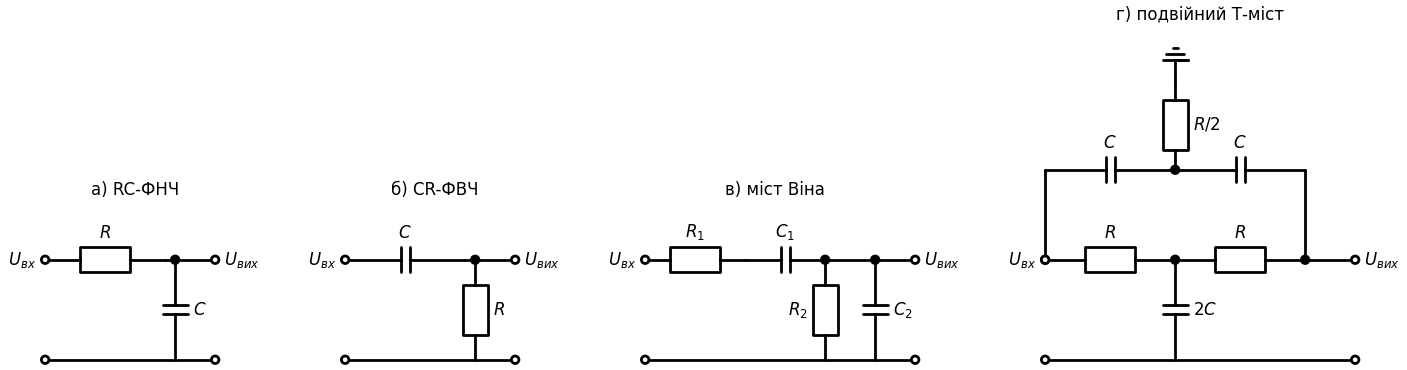

In [3]:
# Елементарні виборчі кола: RC-ФНЧ, CR-ФВЧ, міст Віна, подвійний Т-міст
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        def ports(ox, xo):
            d.add(elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left')); d.add(elm.Dot(open=True).at((ox, 0)))
            d.add(elm.Dot(open=True).at((xo, 2)).label('$U_{вих}$', loc='right')); d.add(elm.Dot(open=True).at((xo, 0)))
            d.add(W((ox, 0), (xo, 0)))
        d += elm.Label().at((1.7, 3.3)).label('а) RC-ФНЧ')
        d += elm.Resistor().at((0, 2)).to((2.4, 2)).label('$R$'); d += W((2.4, 2), (3.4, 2)); d += elm.Dot().at((2.6, 2))
        d += elm.Capacitor().at((2.6, 2)).to((2.6, 0)).label('$C$', loc='bottom'); ports(0, 3.4)
        ox = 6
        d += elm.Label().at((ox + 1.7, 3.3)).label('б) CR-ФВЧ')
        d += elm.Capacitor().at((ox, 2)).to((ox + 2.4, 2)).label('$C$'); d += W((ox + 2.4, 2), (ox + 3.4, 2)); d += elm.Dot().at((ox + 2.6, 2))
        d += elm.Resistor().at((ox + 2.6, 2)).to((ox + 2.6, 0)).label('$R$', loc='bottom'); ports(ox, ox + 3.4)
        ox = 12
        d += elm.Label().at((ox + 2.5, 3.3)).label('в) міст Віна')
        d += elm.Resistor().at((ox, 2)).to((ox + 2.0, 2)).label('$R_1$'); d += elm.Capacitor().at((ox + 2.0, 2)).to((ox + 3.6, 2)).label('$C_1$')
        d += elm.Dot().at((ox + 3.6, 2)); d += W((ox + 3.6, 2), (ox + 5.4, 2))
        d += elm.Resistor().at((ox + 3.6, 2)).to((ox + 3.6, 0)).label('$R_2$', loc='top')
        d += elm.Dot().at((ox + 4.6, 2)); d += elm.Capacitor().at((ox + 4.6, 2)).to((ox + 4.6, 0)).label('$C_2$', loc='bottom')
        ports(ox, ox + 5.4)
        ox = 20
        d += elm.Label().at((ox + 3.0, 6.8)).label('г) подвійний Т-міст')
        d += elm.Resistor().at((ox, 2)).to((ox + 2.6, 2)).label('$R$'); d += elm.Resistor().at((ox + 2.6, 2)).to((ox + 5.2, 2)).label('$R$')
        d += elm.Dot().at((ox + 2.6, 2)); d += elm.Capacitor().at((ox + 2.6, 2)).to((ox + 2.6, 0)).label('$2C$', loc='bottom')
        d += elm.Dot().at((ox, 2)); d += W((ox, 2), (ox, 3.8)); d += elm.Capacitor().at((ox, 3.8)).to((ox + 2.6, 3.8)).label('$C$')
        d += elm.Capacitor().at((ox + 2.6, 3.8)).to((ox + 5.2, 3.8)).label('$C$'); d += W((ox + 5.2, 3.8), (ox + 5.2, 2)); d += elm.Dot().at((ox + 5.2, 2))
        d += elm.Dot().at((ox + 2.6, 3.8)); d += elm.Resistor().at((ox + 2.6, 3.8)).to((ox + 2.6, 5.6)).label('$R/2$', loc='bottom')
        d += elm.Ground().theta(180).at((ox + 2.6, 5.6))
        ports(ox - 0.0, ox + 6.2); d += W((ox + 5.2, 2), (ox + 6.2, 2))

---
### 🔬 Інтерактивно: АЧХ і ФЧХ елементарних виборчих кіл <a class="anchor" id="rc-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Розраховані АЧХ і ФЧХ для однакових $R$ і $C$ ($f_0 = 1/2\pi RC$). Міст Віна має максимум 1/3 і нульову фазу на $f_0$; подвійний Т-міст — нуль передачі на $f_0$ (у реальному мосту — скінченна глибина через розкид елементів: змініть «розбаланс»); трьохланковий RC-ланцюжок дає $-180°$ на $f_0/\sqrt6$.

</div>

In [4]:
# АЧХ/ФЧХ: RC-ФНЧ, міст Віна, подвійний Т-міст, трьохланковий RC-ланцюжок
def rc_circuits(R_k=10.0, C_nF=10.0, mismatch_pct=0.0):
    R, C = R_k * 1e3, C_nF * 1e-9
    f0 = 1 / (2 * np.pi * R * C)
    f = np.logspace(np.log10(f0) - 2, np.log10(f0) + 2, 2000); s = 2j * np.pi * f
    K = {}
    K['RC-ФНЧ'] = 1 / (1 + s * R * C)
    Zs = R + 1 / (s * C); Zp = R / (1 + s * R * C); K['міст Віна'] = Zp / (Zs + Zp)
    # подвійний Т-міст без навантаження: вузлові рівняння (вузли: середина RR — a, середина CC — b, вихід — o)
    k = 1 + mismatch_pct / 100
    Y1, Y2, Y3 = 1 / R, 1 / R, s * 2 * C * k
    Y4, Y5, Y6 = s * C, s * C, 2 / R
    Kt = []
    for i in range(len(f)):
        A = np.array([[Y1 + Y2 + Y3[i], 0, -Y2], [0, Y4[i] + Y5[i] + Y6, -Y5[i]], [-Y2, -Y5[i], Y2 + Y5[i]]])
        b = np.array([Y1, Y4[i], 0])
        Kt.append(np.linalg.solve(A, b)[2])
    K['подвійний Т-міст'] = np.array(Kt)
    x = s * R * C; K['RC-ланцюжок (3 ланки, ФВЧ)'] = x ** 3 / (x ** 3 + 6 * x ** 2 + 5 * x + 1)
    cols = ['#9E9E9E', '#2196F3', '#F44336', '#4CAF50']
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.3))
    for (name, k_), col in zip(K.items(), cols):
        a1.semilogx(f / f0, db(k_), color=col, label=name); ph = np.degrees(np.unwrap(np.angle(k_))); ph += 360 if 'ланцюжок' in name else 0     # фаза CR-ланцюжка: +270° … 0°
        a2.semilogx(f / f0, ph, color=col)
    for a in (a1, a2):
        a.axvline(1, color='k', ls=':', lw=1); a.set_xlabel('$f/f_0$')
    a1.axvline(1 / np.sqrt(6), color='#4CAF50', ls=':', lw=1)
    a1.set_ylim(-60, 3); a1.set_ylabel('дБ'); a1.legend(fontsize=9, loc='lower right'); a1.set_title(f'АЧХ, $f_0$ = {f0:.0f} Гц')
    a2.set_ylabel('φ, град'); a2.set_title('ФЧХ')
    plt.tight_layout(); plt.show()
    i0 = np.argmin(abs(f - f0))
    print(f'Міст Віна на f0: |K| = {abs(K["міст Віна"][i0]):.3f} (1/3);  подвійний Т на f0: {db(K["подвійний Т-міст"][i0]):.1f} дБ;  '
          f'RC-ланцюжок на f0/√6: |K| = {abs(K["RC-ланцюжок (3 ланки, ФВЧ)"][np.argmin(abs(f - f0/np.sqrt(6)))]):.4f} (1/29 = 0,0345)')

interact(rc_circuits,
         R_k=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='R (кОм)'),
         C_nF=widgets.FloatSlider(min=1, max=100, step=1, value=10, description='C (нФ)'),
         mismatch_pct=widgets.FloatSlider(min=0, max=10, step=0.5, value=0, description='розбаланс (%)'));

interactive(children=(FloatSlider(value=10.0, description='R (кОм)', min=1.0, step=1.0), FloatSlider(value=10.…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Порядок фільтра не дорівнює кількості ОП.** Порядок визначається числом конденсаторів (полюсів): ланка Саллена–Кі або MFB на одному ОП має 2-й порядок, а пасивна RC-ланка без ОП — 1-й. Також: «частота зрізу» Чебишова зазвичай задається на рівні пульсацій, а не −3 дБ, а для Бесселя — часто за груповою затримкою; порівнювати фільтри треба за однаковим визначенням.

</div>

---
### ⚡ Практичне застосування: вибір фільтра

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Задача | Рекомендований тип |
|---|---|
| Антиелайзинговий фільтр звукового АЦП | Баттерворт / еліптичний високого порядку |
| Передача імпульсів, осцилографи, цифрові лінії | Бессель |
| Розділення близьких каналів, мінімальна кількість ланок | Чебишов, еліптичний |
| Придушення мережевої завади 50 Гц в ЕКГ | загороджувальний (twin-T з ОП) |
| Кросовер акустичних систем | Лінквіца–Райлі (два каскади Баттерворта) |
| Фазова корекція, обертання фази | фазовий (всепропускний) фільтр |

</div>

---
### ✅ Питання для самоперевірки: основи активних фільтрів

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Що таке порядок фільтра і як він впливає на АЧХ?</summary>

> **Відповідь:** Степінь знаменника передавальної функції (кількість полюсів, реактивних елементів). Асимптотичний нахил АЧХ поза СП дорівнює $20n$ дБ/дек.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чим відрізняються фільтри Баттерворта, Чебишова і Бесселя?</summary>

> **Відповідь:** Баттерворт — максимально плоска АЧХ; Чебишов — пульсації в СП, але крутіший спад; Бессель — найлінійніша ФЧХ (без викиду на імпульсах), але пологий спад.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому активні фільтри будують каскадом ланок 2-го порядку?</summary>

> **Відповідь:** Поліном розкладається на множники 2-го порядку, а ОП розв'язує ланки — їх можна розраховувати незалежно.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Який коефіцієнт передачі моста Віна на $f_0$?</summary>

> **Відповідь:** $1/3$ при нульовому фазовому зсуві.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чим цікавий подвійний Т-міст?</summary>

> **Відповідь:** На $f_0 = 1/2\pi RC$ його коефіцієнт передачі дорівнює нулю — це режекторне коло.

</details>

---
### 📝 Задачі для самостійного розв'язання: основи фільтрів


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Скільки потрібно порядків фільтра Баттерворта, щоб на частоті вдвічі вищій за $f_c$ послаблення було не менше 40 дБ?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $n \ge \lg(10^4 - 1)/(2\lg2) = 6{,}64 \Rightarrow n = 7$.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Розрахуйте міст Віна на $f_0 = 1$ кГц, якщо $C = 10$ нФ.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R = 1/(2\pi f_0C) = 15{,}9$ кОм (стандартний 16 кОм).

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** RC-ФНЧ має $R = 4{,}7$ кОм, $C = 33$ нФ. Знайдіть $f_з$ та послаблення на 10 кГц.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $f_з = 1026$ Гц; $|K| = 1/\sqrt{1 + (10^4/1026)^2} \approx 0{,}102$ (−19,8 дБ).

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Поняття | Співвідношення |
|---|---|
| Порядок фільтра | $n$ — степінь знаменника; нахил $20n$ дБ/дек |
| Ланка 2-го порядку | $K = \dfrac{K_0\omega_0^2}{p^2 + p\omega_0/Q + \omega_0^2}$ |
| Баттерворт | $|K| = K_0/\sqrt{1 + (\omega/\omega_з)^{2n}}$ |
| RC-ФНЧ / CR-ФВЧ | $f_з = 1/(2\pi RC)$ |
| Міст Віна | $f_0 = 1/(2\pi RC)$, $K(f_0) = 1/3$, $\varphi = 0$ |
| Подвійний Т-міст | $f_0 = 1/(2\pi RC)$, $K(f_0) = 0$ |
| RC-ланцюжок | $\varphi = 180°$ при $f = 1/(2\pi\sqrt6 RC)$, $|K| = 1/29$ |

**Головні висновки.** Активні фільтри замінюють котушки комбінацією RC-кіл і ОП. Вид АЧХ задається призначенням (ФНЧ, ФВЧ, СФ, ЗФ, фазовий), форма в перехідній смузі — апроксимацією (компроміс між крутизною, нерівномірністю і фазовими спотвореннями), крутизна спаду — порядком. Мости Віна, подвійний Т і RC-ланцюжки є «цеглинками» і фільтрів, і RC-генераторів.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Williams A. B., Taylor F. J. Electronic Filter Design Handbook. — 4th ed. — McGraw-Hill, 2006.
7. Мошиц Г., Хорн П. Проектирование активных фильтров. — М.: Мир, 1984.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 9. Нелінійні схеми на ОП: компаратори, тригери Шмітта, прецизійні випрямлячі](Тема_09_Нелінійні_схеми_на_ОП.ipynb) &nbsp;|&nbsp; [Тема 11. Активні фільтри на ОП: ФНЧ, ФВЧ, смугові, загороджувальні, фазові](Тема_11_Активні_фільтри_на_ОП.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*